# 8 · SIMP et compliance : un mini top88

*Notebook 8 du cours. Il suppose les notebooks 6 (opérateur sans matrice) et 7 (état adjoint, `solve_spd`).*

Jusqu'ici le matériau était donné. Ici on laisse l'ordinateur **décider où mettre de la matière** : on cherche la répartition de densité $\rho_e\in[0,1]$ dans une boîte, à volume fixé, qui rend la structure la plus raide possible pour un chargement donné. C'est l'optimisation topologique, et ce notebook en assemble la version la plus simple, celle de **top88** (Andreassen et al., 2011) : SIMP pour interpoler la rigidité, la compliance comme coût, l'état adjoint pour son gradient, le critère d'optimalité (OC) pour mettre à jour la densité.

**Plan.**
1. SIMP : pourquoi pénaliser les densités intermédiaires (deux barres en parallèle, où tout se calcule) ;
2. Le problème et ses sensibilités ;
3. Le critère d'optimalité (OC), dérivé puis vérifié sur un problème à solution connue ;
4. La boucle complète et sa validation contre un top88 NumPy indépendant ;
5. Résultat sur la poutre MBB et vérification des conditions d'optimalité ;
6. Le rôle de l'exposant $p$ ;
7. Les damiers et la dépendance au maillage, qui motivent la leçon 9 ;
8. Coût par itération, et le même code en 3D.

Ce notebook promeut dans `src` : `topopt/density.py::simp`, `objectives/mechanical.py::compliance`, `optim/oc.py::OC`, et les conditions aux limites `fem/bc.py` (appuis, charges, cas nommés `mbb` et `cantilever`). L'oracle de comparaison est `tests/reference/top88_numpy.py`, qui ne partage aucun code avec le paquet.

In [1]:
import sys, time, inspect
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "aeroptimizer").is_dir())
sys.path.insert(0, str(RACINE / "src"))
sys.path.insert(0, str(RACINE / "tests"))

from aeroptimizer.fem import elements as el
from aeroptimizer.fem.adjoint import solve_spd
from aeroptimizer.fem.bc import build_case
from aeroptimizer.fem.operators import StructuredFEOperator
from aeroptimizer.fem.solvers import DirectHandle, ScipyDirect
from aeroptimizer.grid import Grid, Connectivity
from aeroptimizer.materials import Orthotropic
from aeroptimizer.objectives.mechanical import compliance
from aeroptimizer.optim.oc import OC
from aeroptimizer.topopt.density import simp
from reference.top88_numpy import top88          # oracle indépendant (aucun code du paquet)

torch.set_default_dtype(torch.float64)       # convention du projet (CONTRACTS C-CONV-03)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})
np.set_printoptions(precision=4, suppress=True, linewidth=120)

## 1. SIMP : pourquoi pénaliser

**Relaxation.** Décider « matière ou vide » élément par élément est un problème combinatoire. On le relâche : $\rho_e\in[0,1]$ est une *densité*, et la rigidité de l'élément est $s(\rho_e)\,\mathbf K_e^0$ avec

$$
s(\rho)=\varepsilon_s+(1-\varepsilon_s)\,\rho^{\,p},\qquad p\ge 1,\quad \varepsilon_s=10^{-9}.
$$

Le petit $\varepsilon_s$ garde $\widetilde{\mathbf K}$ définie positive quand un élément est vide (notebook 5). L'exposant $p$ (SIMP : *Solid Isotropic Material with Penalization*) est le sujet de cette section.

**Deux barres en parallèle** montrent le mécanisme. Une force $F$ tire sur deux barres de même longueur et même rigidité $k$, de densités $\rho_1,\rho_2$ avec $\rho_1+\rho_2=1$ (le volume est imposé). Les rigidités s'ajoutent, donc

$$
\mathcal C=\frac{F^2}{k\,[\,s(\rho_1)+s(\rho_2)\,]}.
$$

- Avec $p=1$ (pas de pénalisation) : $s(\rho_1)+s(\rho_2)=\rho_1+\rho_2=1$ (à $\varepsilon_s$ près), donc $\mathcal C$ **ne dépend pas** de la répartition. Tous les designs se valent, y compris le gris uniforme $\rho_1=\rho_2=\tfrac12$ : le problème relâché n'a aucune raison de produire du noir et blanc.
- Avec $p>1$ : $\rho^p$ est convexe, donc $s(\rho_1)+s(\rho_2)$ est **maximale aux extrémités** ($\rho_1=1,\rho_2=0$) et minimale au milieu. Le gris $\tfrac12/\tfrac12$ n'offre que $2\cdot2^{-p}$ de la rigidité de la barre pleine, pour le même volume : la matière intermédiaire est *inefficace*, l'optimum est tout dans une barre.

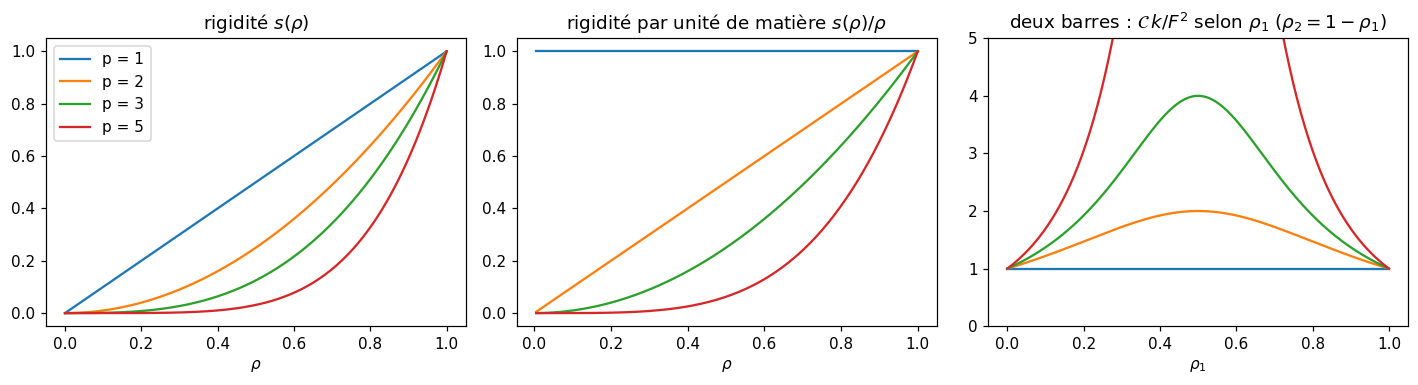

p = 1 : C k/F^2 = 1.0000 (une barre pleine)  1.0000 (gris 1/2-1/2)  1.0000
p = 3 : C k/F^2 = 1.0000 (une barre pleine)  4.0000 (gris 1/2-1/2)  1.0000


In [2]:
eps_s = 1e-9
rho = torch.linspace(0, 1, 201)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for p in (1, 2, 3, 5):
    s = simp(rho, p, eps_s)
    ax[0].plot(rho, s, label=f"p = {p}")
    ax[1].plot(rho[1:], s[1:] / rho[1:], label=f"p = {p}")
    r1 = torch.linspace(0, 1, 201)
    ax[2].plot(r1, 1.0 / (simp(r1, p, eps_s) + simp(1 - r1, p, eps_s)), label=f"p = {p}")
ax[0].set(title="rigidité $s(\\rho)$", xlabel="$\\rho$"); ax[0].legend()
ax[1].set(title="rigidité par unité de matière $s(\\rho)/\\rho$", xlabel="$\\rho$")
ax[2].set(title="deux barres : $\\mathcal{C}\\,k/F^2$ selon $\\rho_1$ ($\\rho_2=1-\\rho_1$)", xlabel="$\\rho_1$", ylim=(0, 5))
plt.tight_layout(); plt.show()

for p in (1, 3):
    c = lambda r1: 1.0 / (simp(torch.tensor(r1), p, eps_s) + simp(torch.tensor(1 - r1), p, eps_s))
    print(f"p = {p} : C k/F^2 = {c(0.0):.4f} (une barre pleine)  {c(0.5):.4f} (gris 1/2-1/2)  {c(1.0):.4f}")

À gauche : $s(\rho)$ s'écarte de la droite $s=\rho$ dès que $p>1$. Au milieu : la rigidité obtenue **par unité de matière** vaut 1 pour $p=1$ (rien ne distingue le gris du plein) et chute pour $p>1$ ($\rho=\tfrac12$, $p=3$ : seulement $\tfrac14$ de la rigidité par unité de matière du plein). À droite : la compliance des deux barres, **plate** pour $p=1$ et en cuvette inversée pour $p>1$ (les extrémités sont les minima).

Ce qu'on paie : pour $p>1$ le problème n'est plus convexe, il peut avoir plusieurs minima locaux (leçon 9 : continuation en $p$). Et il faut que le matériau « gris » ait un sens : le facteur $\rho^p$ n'est pas un vrai matériau, c'est un artifice pour pousser vers 0 ou 1. C'est pourquoi on exigera que le résultat final soit *presque* noir et blanc (voir §5 et §6).

## 2. Le problème et ses sensibilités

$$
\min_{\boldsymbol\rho\in[0,1]^{N_e}}\ \mathcal C(\boldsymbol\rho)=\mathbf f^\top\mathbf u(\boldsymbol\rho)
\quad\text{avec}\quad \widetilde{\mathbf K}\big(s(\boldsymbol\rho)\big)\,\mathbf u=\mathbf P\mathbf f,
\qquad\text{sous}\quad g(\boldsymbol\rho)=\frac{1}{V^{*}N_e}\sum_e\rho_e-1\le 0,
$$

où $V^{*}$ est la fraction de volume autorisée. Par le notebook 7 (cas $\boldsymbol\lambda=\mathbf u$) :

$$
\frac{\partial\mathcal C}{\partial\rho_e}=-\,p\,(1-\varepsilon_s)\,\rho_e^{\,p-1}\ \mathbf u_e^\top\mathbf K_e^0\,\mathbf u_e\ \le 0,
\qquad \frac{\partial g}{\partial\rho_e}=\frac{1}{V^{*}N_e}>0 .
$$

La compliance est une fonction **décroissante** de chaque densité : ajouter de la matière ne peut qu'aider. C'est pourquoi la contrainte de volume est active à l'optimum, et c'est le signe sur lequel repose l'OC. Le terme $\mathbf u_e^\top\mathbf K_e^0\mathbf u_e$ est (au double près) l'**énergie de déformation** de l'élément : on renforce là où la structure travaille.

**Le cas de test : la poutre MBB.** On modélise la moitié d'une poutre posée sur deux appuis et chargée en son milieu (*Messerschmitt–Bölkow–Blohm*), grâce au plan de symétrie : $u_x=0$ sur le bord gauche, un appui simple ($u_z=0$) sous le coin droit, force unitaire vers le bas en haut à gauche. Le code des conditions aux limites est `build_case("mbb", grid)` (`fem/bc.py`) ; il vérifie que les appuis bloquent bien les 3 mouvements de corps rigide (test C-BC-01).

MBB 60x20 : 1200 éléments, 2562 ddl, 22 ddl bloqués, charge totale = [0.0, -1.0]
C(rho = 0.5) = 1007.022
gradient adjoint vs formule : erreur relative max = 1.9e-16
dC/drho <= 0 partout : True


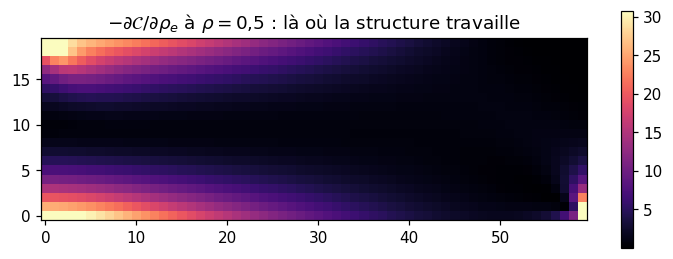

In [3]:
def cas(shape, nom):
    # opérateur et second membre d'un cas nommé, matériau isotrope E = 1, nu = 0.3 (contraintes planes en 2D)
    g = Grid(shape, (1.0,) * len(shape))
    d = g.d
    fixe, charge, _ = build_case(nom, g)
    Ke0 = el.elasticity_ke0(d, g.h, Orthotropic.isotropic(1.0, 0.3).stiffness(d))
    op = StructuredFEOperator(g, Connectivity(g, d), Ke0, d, fixe)
    return op, charge.assemble(torch.ones(g.shape))

def montre(ax, x, shape, titre="", miroir=False):
    # densité 2D, axe z vers le haut ; miroir=True reconstitue la poutre MBB entière
    img = np.asarray(x).reshape(shape).T
    if miroir:
        img = np.hstack([img[:, ::-1], img])
    ax.imshow(img, origin="lower", cmap="gray_r", vmin=0, vmax=1, interpolation="nearest")
    ax.set_title(titre); ax.set_xticks([]); ax.set_yticks([])

nx, nz, vf, p = 60, 20, 0.5, 3.0
op, f = cas((nx, nz), "mbb")
print(f"MBB {nx}x{nz} : {op.grid.n_elems} éléments, {op.n_dofs} ddl, {int((~op.free_mask).sum())} ddl bloqués, "
      f"charge totale = {f.reshape(-1, 2).sum(0).tolist()}")

# densité uniforme = vf : gradient par l'adjoint (autograd + solve_spd) contre la formule ci-dessus
rho0 = torch.full((op.grid.n_elems,), vf, requires_grad=True)
u = solve_spd(op, simp(rho0, p), f, ScipyDirect())
C0 = compliance(f, u); C0.backward()
formule = -p * (1 - 1e-9) * rho0.detach() ** (p - 1) * op.dK_contract(u, u)
print(f"C(rho = {vf}) = {C0.item():.3f}")
print(f"gradient adjoint vs formule : erreur relative max = {((rho0.grad - formule).abs().max() / formule.abs().max()).item():.1e}")
print(f"dC/drho <= 0 partout : {bool((rho0.grad <= 0).all())}")

fig, ax = plt.subplots(figsize=(8, 2.8))
sens = (-rho0.grad).detach().numpy().reshape(nx, nz).T
im = ax.imshow(sens, origin="lower", cmap="magma", vmax=np.percentile(sens, 99))   # coins (charge, appui) saturés
ax.set_title(r"$-\partial\mathcal{C}/\partial\rho_e$ à $\rho=0{,}5$ : là où la structure travaille"); plt.colorbar(im); plt.show()

Le gradient de l'adjoint coïncide avec la formule à la précision machine (c'est le test C-SOLVE-06 du notebook 7, ici sur la MBB) et il est négatif partout. La carte montre les zones de forte énergie de déformation : le voisinage de la force (en haut à gauche), de l'appui, et la ligne médiane (la traction en bas, la compression en haut). L'optimiseur va renforcer ces zones et retirer de la matière là où le gradient est proche de 0. (L'échelle de couleur est saturée au 99e centile : les deux éléments d'angle sous la force et sur l'appui, singuliers, sont 10 fois plus énergétiques que le reste.)

## 3. Le critère d'optimalité (OC)

Le lagrangien est $\mathcal L=\mathcal C+\Lambda\,g$ ($\Lambda\ge0$ le multiplicateur du volume). Pour un élément **strictement entre les bornes** ($0<\rho_e<1$) la stationnarité s'écrit

$$
\frac{\partial\mathcal C}{\partial\rho_e}+\Lambda\,\frac{\partial g}{\partial\rho_e}=0
\quad\Longleftrightarrow\quad
B_e:=\frac{-\,\partial\mathcal C/\partial\rho_e}{\Lambda\,\partial g/\partial\rho_e}=1 .
$$

$B_e$ compare le gain de compliance par unité de matière ajoutée à un « prix » commun $\Lambda$ : si $B_e>1$ l'élément « vaut plus qu'il ne coûte » (il faut l'épaissir), si $B_e<1$ il faut l'alléger. À l'optimum, $B_e=1$ pour les éléments intermédiaires, $B_e\le1$ pour ceux à $\rho_e=0$ et $B_e\ge1$ pour ceux à $\rho_e=1$ (conditions KKT).

**L'itération OC** en fait un point fixe : $\rho_e\leftarrow\rho_e\,B_e^{\,\eta}$ avec un amortissement $\eta=\tfrac12$, une limite de déplacement $|\Delta\rho_e|\le m=0{,}2$ et les bornes $[0,1]$, soit

$$
\rho_e^{\text{new}}=\operatorname{clip}\Big(\rho_e\,B_e^{\,\eta},\ \max(0,\rho_e-m),\ \min(1,\rho_e+m)\Big).
$$

$\Lambda$ n'est pas connu : on le **cherche par bissection** pour que le volume du design mis à jour soit exactement $V^{*}$ (le volume décroît quand $\Lambda$ croît). C'est tout l'algorithme (`optim/oc.py`) :

In [4]:
print(inspect.getsource(OC.step))

    def step(
        self, x: np.ndarray, f: float, df: np.ndarray, g: float, dg: np.ndarray
    ) -> np.ndarray:
        """Bisection on the multiplier lam; keeps x in [0,1] exactly (C-OPT-01).

        `g` is the constraint value (feasible when <= 0) and `dg` its gradient. The constraint is
        linearised around `x`, which is exact for the volume. Bisection stops when the bracket is
        narrower than `tol` (relative; top88 uses 1e-3, the default here is tighter) and the
        returned point is the feasible end of the bracket (top88 returns the last midpoint).
        """
        x = np.asarray(x, dtype=float)
        lo = np.clip(x - self.move, 0.0, 1.0)
        hi = np.clip(x + self.move, 0.0, 1.0)
        ratio = np.maximum(-np.asarray(df, dtype=float), 0.0) / np.maximum(dg, 1e-30)
        l1, l2 = 0.0, 1e9
        for _ in range(self.max_bisect):
            if (l2 - l1) <= self.tol * (l1 + l2):
                break
            lmid = 0.5 * (l1 + l2)
            x_try 

La contrainte est **linéarisée** autour de $\mathbf x$ ($g+\nabla g\cdot\Delta\mathbf x$), ce qui est exact pour le volume ; `OC.step(x, f, df, g, dg)` reste donc générique (une contrainte $g\le0$ et son gradient). Le point renvoyé est l'extrémité *admissible* de l'intervalle de bissection (le top88 d'origine renvoie le dernier point milieu, à $10^{-3}$ près en volume ; ici la tolérance par défaut est $10^{-6}$).

**Premier test, sur un problème dont la solution se calcule à la main.** $N$ ressorts en série, de « souplesses » $a_e>0$, avec SIMP $p=2$ et sans $\varepsilon_s$ : $\mathcal C=\sum_e a_e/\rho_e^{2}$, sous $\sum_e\rho_e=NV^{*}$. Les conditions $\partial\mathcal C/\partial\rho_e=-2a_e/\rho_e^3=-\Lambda/N$ donnent $\rho_e\propto a_e^{1/3}$, donc

$$
\rho_e^\star=N V^{*}\ \frac{a_e^{1/3}}{\sum_f a_f^{1/3}} .
$$

(Avec $p=1$ le point fixe $\rho\,B^{1/2}$ tomberait sur la solution en une seule itération, ce qui ne testerait pas la convergence ; $p=2$ oblige à itérer.)

In [5]:
N, V = 10, 0.4
a = np.linspace(1.0, 4.0, N)
rho_exact = N * V * a ** (1 / 3) / (a ** (1 / 3)).sum()
print("solution exacte :", rho_exact, f"(max = {rho_exact.max():.3f} < 1 : aucune borne active)")

oc = OC(tol=1e-12)
x = np.full(N, V)                                    # départ : densité uniforme, volume exact
err = []
for it in range(40):
    df = -2 * a / x**3                               # dC/drho_e
    x = oc.step(x, (a / x**2).sum(), df, x.mean() / V - 1.0, np.full(N, 1.0 / (N * V)))
    err.append(np.abs(x - rho_exact).max())
print("OC après 40 itérations :", x)
print("erreur max à la solution exacte, itérations 1, 2, 5, 10, 20, 40 :", " ".join(f"{err[k - 1]:.1e}" for k in (1, 2, 5, 10, 20, 40)))
print(f"rapport d'erreurs successives (itérations 10 -> 11) : {err[10] / err[9]:.2f}")
print(f"volume : {x.mean():.12f} (cible {V})")

solution exacte : [0.3002 0.3304 0.3559 0.3782 0.3982 0.4163 0.433  0.4484 0.4629 0.4765] (max = 0.477 < 1 : aucune borne active)
OC après 40 itérations : [0.3002 0.3304 0.3559 0.3782 0.3982 0.4163 0.433  0.4484 0.4629 0.4765]
erreur max à la solution exacte, itérations 1, 2, 5, 10, 20, 40 : 4.2e-02 2.3e-02 2.8e-03 8.7e-05 8.5e-08 3.4e-13
rapport d'erreurs successives (itérations 10 -> 11) : 0.50
volume : 0.400000000000 (cible 0.4)


L'OC retrouve la solution analytique, avec une convergence linéaire (l'erreur est divisée par un facteur constant à chaque itération : le point fixe est contractant). C'est un test de l'algorithme **seul** : le §4 testera l'ensemble de la boucle (éléments finis, adjoint, OC) contre un code indépendant.

## 4. La boucle complète

À chaque itération : (1) densité $\to$ rigidités $s=\operatorname{simp}(\boldsymbol\rho)$ ; (2) état $\mathbf u=$ `solve_spd(...)` ; (3) $\mathcal C=\mathbf f^\top\mathbf u$ ; (4) `C.backward()` donne $\partial\mathcal C/\partial\boldsymbol\rho$ via l'adjoint ; (5) `OC.step` met à jour. Les étapes (1) à (4) sont les briques des notebooks 6 et 7 ; il n'y a **aucune dérivée écrite à la main** dans la boucle.

In [6]:
def mini_top88(op, f, vf, p, n_iter, oc=None, solveur=None, tol_dx=None, x0=None):
    # SIMP + adjoint + OC. Renvoie la densité finale et l'historique {C, dx, vol, grise}.
    oc, solveur = oc or OC(), solveur or ScipyDirect()
    n = op.grid.n_elems
    dg = np.full(n, 1.0 / (n * vf))                  # d g / d rho_e pour g = mean(rho)/vf - 1
    x = np.full(n, vf) if x0 is None else np.asarray(x0, dtype=float).copy()
    hist = {"C": [], "dx": [], "df": None}
    for it in range(n_iter):
        rho = torch.from_numpy(x).requires_grad_()
        C = compliance(f, solve_spd(op, simp(rho, p), f, solveur))
        C.backward()
        df = rho.grad.numpy()
        x_new = oc.step(x, C.item(), df, x.mean() / vf - 1.0, dg)
        hist["C"].append(C.item()); hist["dx"].append(np.abs(x_new - x).max()); hist["df"] = df
        x = x_new
        if tol_dx is not None and hist["dx"][-1] < tol_dx:
            break
    hist["C"], hist["dx"] = np.array(hist["C"]), np.array(hist["dx"])
    return x, hist

print(inspect.getsource(mini_top88).count("\n"), "lignes")

19 lignes


**Validation contre un top88 indépendant.** `tests/reference/top88_numpy.py` est un portage du code de 88 lignes d'Andreassen et al. : sa propre matrice élémentaire (formule fermée), son propre assemblage COO, `spsolve`, et sa propre bissection d'OC. Il ne partage rien avec le paquet. On le lance **sans filtre** (`ft=0`, un cas que le code d'origine n'a pas mais qui est l'objet de ce notebook), avec la même tolérance de bissection ($10^{-12}$ pour les deux, afin que le chemin de bissection n'influe pas), 40 itérations exactement. La grille du top88 a la ligne 0 en haut ; on retourne son résultat pour le comparer au nôtre.

In [7]:
n_it = 40
ref = top88(nx, nz, vf, p, 1.0, max_iter=n_it, ft=0, lam_tol=1e-12, change_tol=0.0)
x40, h40 = mini_top88(op, f, vf, p, n_it, oc=OC(tol=1e-12))

x_ref = np.flipud(ref["x"]).T.reshape(-1)           # (lignes depuis le haut, colonnes) -> (x, z vers le haut)
print(f"{'itération':>10} | {'C (mini top88)':>16} | {'C (oracle)':>16} | écart relatif")
for it in (0, 1, 4, 9, 19, 39):
    print(f"{it + 1:10d} | {h40['C'][it]:16.9f} | {ref['c'][it]:16.9f} | {abs(h40['C'][it] / ref['c'][it] - 1):.1e}")
print(f"écart relatif max sur les {n_it} compliances : {np.max(np.abs(h40['C'] / np.array(ref['c']) - 1)):.1e}")
print(f"écart max sur la densité finale             : {np.abs(x40 - x_ref).max():.1e}")
print(f"volume : {x40.mean():.12f} (cible {vf})")

 itération |   C (mini top88) |       C (oracle) | écart relatif
         1 |   1007.022100725 |   1007.022100723 | 1.8e-12
         2 |    577.034915837 |    577.034915843 | 9.2e-12
         5 |    318.425327827 |    318.425327826 | 2.5e-12
        10 |    253.566772568 |    253.566772568 | 9.2e-13
        20 |    204.934004279 |    204.934004272 | 3.2e-11
        40 |    203.210865553 |    203.210865552 | 4.2e-12
écart relatif max sur les 40 compliances : 4.0e-10
écart max sur la densité finale             : 3.2e-08
volume : 0.500000000000 (cible 0.5)


Deux codes écrits différemment (assemblage par boucle d'indices contre opérateur sans matrice, `spsolve` contre factorisation réutilisée, dérivée par adjoint contre formule fermée de top88) donnent la même suite de compliances à $\sim10^{-9}$ près sur 40 itérations, et la même densité à $\sim10^{-8}$ près. C'est la validation de toute la chaîne des notebooks 4 à 7 sur un problème d'optimisation réel.

## 5. Résultat sur la poutre MBB

On laisse converger : arrêt quand la plus grande variation de $\rho$ passe sous $0{,}01$ (critère de top88), au plus 500 itérations. La figure montre la moitié calculée et la poutre entière (par symétrie), l'historique de la compliance, et celui de la variation maximale.

63 itérations en 0.3 s ; compliance 1007.0 -> 203.21


après 200 itérations : C = 203.2108, variation max 3.6e-03
hausses de C sur 200 itérations : 66, la plus forte : 7.0e-09 (relatif) ; hausses sur les 30 premières : 0


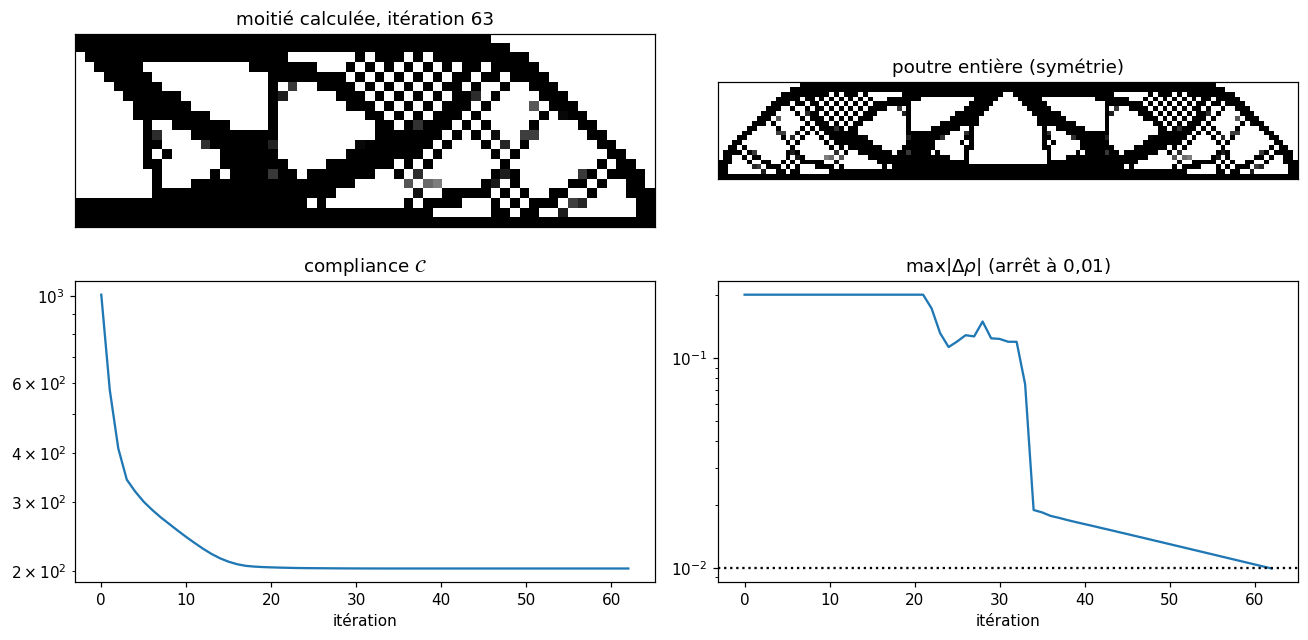

éléments gris (0,1 < rho < 0,9) : 1.8 %
seuillé à 0,5 : volume = 0.5042, compliance = 202.80 (contre 203.21 avant seuillage)


In [8]:
t0 = time.perf_counter()
x, h = mini_top88(op, f, vf, p, 500, tol_dx=0.01)
dt = time.perf_counter() - t0
print(f"{len(h['C'])} itérations en {dt:.1f} s ; compliance {h['C'][0]:.1f} -> {h['C'][-1]:.2f}")
x_long, h_long = mini_top88(op, f, vf, p, 200)       # 200 itérations : la variation continue de baisser
print(f"après 200 itérations : C = {h_long['C'][-1]:.4f}, variation max {h_long['dx'][-1]:.1e}")
dC = np.diff(h_long["C"]) / h_long["C"][:-1]
print(f"hausses de C sur 200 itérations : {int((dC > 0).sum())}, la plus forte : {dC.max():.1e} (relatif) ; hausses sur les 30 premières : {int((dC[:30] > 0).sum())}")

fig, ax = plt.subplots(2, 2, figsize=(12, 6.2))
montre(ax[0, 0], x, (nx, nz), f"moitié calculée, itération {len(h['C'])}")
montre(ax[0, 1], x, (nx, nz), "poutre entière (symétrie)", miroir=True)
ax[1, 0].semilogy(h["C"]); ax[1, 0].set(xlabel="itération", title="compliance $\\mathcal{C}$")
ax[1, 1].semilogy(h["dx"]); ax[1, 1].axhline(0.01, color="k", ls=":"); ax[1, 1].set(xlabel="itération", title="$\\max|\\Delta\\rho|$ (arrêt à 0,01)")
plt.tight_layout(); plt.show()

grise = lambda x: float(((x > 0.1) & (x < 0.9)).mean())
print(f"éléments gris (0,1 < rho < 0,9) : {100 * grise(x):.1f} %")
x_bw = (x > 0.5).astype(float)
with torch.no_grad():
    C_bw = compliance(f, solve_spd(op, simp(torch.from_numpy(x_bw), p), f, ScipyDirect())).item()
print(f"seuillé à 0,5 : volume = {x_bw.mean():.4f}, compliance = {C_bw:.2f} (contre {h['C'][-1]:.2f} avant seuillage)")

On reconnaît la forme classique : deux membrures (haut en compression, bas en traction) reliées par des diagonales, mais aussi des **zones en damier** (voir §7). La compliance est divisée par cinq (1007 $\to$ 203) et la majeure partie de la baisse a lieu dans les premières itérations. Quelques points à noter :
- **Pas de garantie de décroissance monotone** : l'OC est une heuristique (un point fixe), pas une descente avec recherche de pas. Sur ce cas, aucune hausse sur les 30 premières itérations et seulement des hausses minuscules ensuite (voir ci-dessus) ; rien ne l'assure dans le cas général.
- **Presque noir et blanc** : très peu d'éléments gris, et le seuillage à 0,5 ne change presque pas la compliance. C'est l'effet de $p=3$ (voir §6).
- **Le critère d'arrêt de top88 est lâche** : la variation $\max|\Delta\rho|$ passe sous 0,01 bien avant que $\mathcal C$ ait fini de bouger à la 4e décimale. Pour comparer des compliances, on fixe un nombre d'itérations ou on resserre le critère.

**Vérification indépendante de l'optimalité (KKT).** Sans rien supposer de l'OC, on calcule $B_e=-\partial\mathcal C/\partial\rho_e\,/\,(\Lambda\,\partial g/\partial\rho_e)$ avec $\Lambda$ estimé sur les éléments intermédiaires, et on vérifie les trois conditions du §3.

In [9]:
df = h_long["df"]                                    # gradient à la dernière itération de la run de 200
x_k = x_long
n = op.grid.n_elems
B = -df / (1.0 / (n * vf))                           # = -dC/drho / (dg/drho), à un facteur Lambda près
inter = (x_k > 0.05) & (x_k < 0.95)
lam = np.median(B[inter])
Bn = B / lam
print(f"{inter.sum()} éléments intermédiaires sur {n}")
print(f"B_e sur les intermédiaires : min {Bn[inter].min():.4f}, max {Bn[inter].max():.4f}   (attendu : 1)")
bas, haut = x_k <= 0.05, x_k >= 0.95
print(f"éléments à rho ~ 0 : {bas.sum()}, dont B_e <= 1 + 1e-3 : {int((Bn[bas] <= 1 + 1e-3).sum())}   (attendu : tous)")
print(f"éléments à rho ~ 1 : {haut.sum()}, dont B_e >= 1 - 1e-3 : {int((Bn[haut] >= 1 - 1e-3).sum())}   (attendu : tous)")

23 éléments intermédiaires sur 1200
B_e sur les intermédiaires : min 0.9889, max 1.0038   (attendu : 1)
éléments à rho ~ 0 : 595, dont B_e <= 1 + 1e-3 : 595   (attendu : tous)
éléments à rho ~ 1 : 582, dont B_e >= 1 - 1e-3 : 582   (attendu : tous)


Les éléments intermédiaires (23 seulement : le design est presque noir et blanc) vérifient $B_e=1$ à 1 % près (la variation de $\rho$ n'est pas tout à fait nulle après 200 itérations), ceux à 0 ont $B_e\le1$ et ceux à 1 ont $B_e\ge1$ : le point trouvé est bien un point KKT du problème discret (un minimum *local*, pas forcément global, §6).

## 6. Le rôle de l'exposant $p$

On refait le calcul (200 itérations) pour $p=1,2,3,4$. Pour $p=1$ le résultat est gris, et sa compliance *calculée* est trompeuse puisque le « gris » n'a de rigidité que par l'artifice $s=\rho$ ; on la **réévalue** donc avec la loi $p=3$, plus proche d'un matériau réel, et après seuillage à 0,5.

  p |  C (loi p) |  % gris | C du même design, loi p=3 |  C après seuillage (p=3)
  1 |     164.35 |    65.6 |                    411.74 |         3478.8 (vol 0.36)
  2 |     185.28 |    11.9 |                    189.83 |          183.9 (vol 0.52)
  3 |     203.21 |     1.8 |                    203.21 |          202.8 (vol 0.50)
  4 |     216.86 |     0.0 |                    216.86 |          216.9 (vol 0.50)


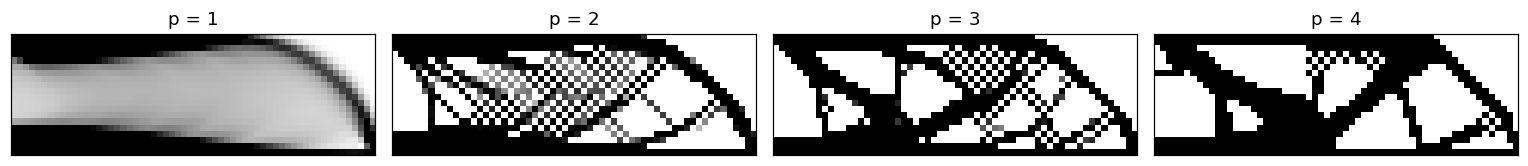

In [10]:
def C_de(x, p_eval, solveur=None):
    with torch.no_grad():
        return compliance(f, solve_spd(op, simp(torch.as_tensor(x, dtype=torch.float64), p_eval), f, solveur or ScipyDirect())).item()

res = {}
for pp in (1.0, 2.0, 3.0, 4.0):
    xx, hh = mini_top88(op, f, vf, pp, 200)
    res[pp] = (xx, hh)
print(f"{'p':>3} | {'C (loi p)':>10} | {'% gris':>7} | {'C du même design, loi p=3':>25} | {'C après seuillage (p=3)':>24}")
for pp, (xx, hh) in res.items():
    seuil = (xx > 0.5).astype(float)
    # un design gris seuillé n'a plus le bon volume : on le dit
    print(f"{pp:3.0f} | {hh['C'][-1]:10.2f} | {100 * grise(xx):7.1f} | {C_de(xx, 3.0):25.2f} | {C_de(seuil, 3.0):14.1f} (vol {seuil.mean():.2f})")

fig, ax = plt.subplots(1, 4, figsize=(14, 2.6))
for a_, (pp, (xx, hh)) in zip(ax, res.items()):
    montre(a_, xx, (nx, nz), f"p = {pp:.0f}")
plt.tight_layout(); plt.show()

- **$p=1$** : le design est gris à plus de moitié et sa compliance « calculée » est la plus basse (164). Mais avec la loi $p=3$, le même design est 2,5 fois moins raide (412) et seuillé il est inutilisable (3 479, le volume tombe à 36 %). La pénalisation n'est pas un détail : elle définit le problème qu'on résout, et les compliances de deux $p$ différents ne se comparent pas telles quelles.
- **$p=3$** est le choix standard de top88 et du projet (FORMALISM §6) : 1,8 % de gris, seuillage quasi sans effet (202,8 contre 203,2). **$p=4$** est tout noir et blanc mais plus *raide à optimiser* : 216,9, soit 7 % de plus.
- **Un minimum local.** Le design obtenu pour $p=2$, **réévalué avec la loi $p=3$**, a une compliance de 189,8, plus basse que celle du design optimisé directement pour $p=3$ (203,2), alors que les deux ont la même densité moyenne. Le design « optimal » pour $p=3$ n'est donc pas un minimum global : la pénalisation durcit la non-convexité, et partir de $\rho=V^{*}$ avec $p=3$ tombe dans un minimum local moins bon. C'est ce que la **continuation en $p$** (commencer à $p=1$ ou 2 puis monter, leçon 9) cherche à éviter.

## 7. Les damiers et la dépendance au maillage

Si le problème était bien posé, raffiner le maillage devrait **préciser** la même forme. Voici l'optimum pour trois résolutions, et la part des blocs $2\times2$ en damier (deux éléments pleins en diagonale, deux vides).

 maillage | C (200 it.) | % gris | % blocs en damier | temps


 (30, 10) |      190.81 |    0.0 |              19.5 | 0.3 s


 (60, 20) |      203.21 |    1.8 |              10.5 | 1.0 s


(120, 40) |      202.15 |    0.5 |               8.3 | 5.1 s


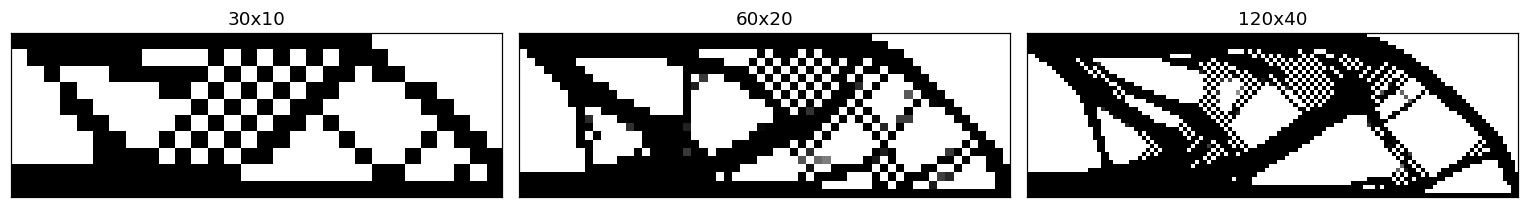

In [11]:
def damier(x, shape):
    z = np.asarray(x).reshape(shape)
    a, b, c, d = z[:-1, :-1], z[1:, :-1], z[:-1, 1:], z[1:, 1:]
    haut, bas = lambda t: t > 0.8, lambda t: t < 0.2
    return float(((haut(a) & haut(d) & bas(b) & bas(c)) | (bas(a) & bas(d) & haut(b) & haut(c))).mean())

fig, ax = plt.subplots(1, 3, figsize=(14, 2.9))
print(f"{'maillage':>9} | {'C (200 it.)':>11} | {'% gris':>6} | {'% blocs en damier':>17} | temps")
for a_, shape in zip(ax, [(30, 10), (60, 20), (120, 40)]):
    o, ff = cas(shape, "mbb")
    t0 = time.perf_counter()
    xx, hh = mini_top88(o, ff, vf, p, 200)
    print(f"{str(shape):>9} | {hh['C'][-1]:11.2f} | {100 * grise(xx):6.1f} | {100 * damier(xx, shape):17.1f} | {time.perf_counter() - t0:.1f} s")
    montre(a_, xx, shape, f"{shape[0]}x{shape[1]}")
plt.tight_layout(); plt.show()

Le raffinement n'affine pas la forme : il **rajoute des barres**, de plus en plus fines (à la limite, des barres infiniment fines : le problème continu n'a pas de solution, il faut imposer une taille minimale). Et des zones en damier apparaissent (blocs $2\times2$ en alternance).

**Pourquoi un damier ?** Il est numériquement trop raide. Test sur une console 2D $40\times20$ (poutre encastrée à gauche, charge répartie sur le bord droit, $\varepsilon_s=10^{-3}$ pour garder le système résoluble) : on compare le plein, un damier de 0 et de 1 (moitié du volume, carrés qui ne se touchent que par un coin) et des bandes alternées de même volume.

In [12]:
class DirectTol:
    # solveur direct à tolérance de résidu relâchée (matrices très mal conditionnées, voir notebook 6)
    def __init__(self, tol): self.tol = tol
    def prepare(self, op, w): return DirectHandle(op.assemble_csr(w), tol=self.tol)

def comparaison(nx_, nz_):
    o, ff = cas((nx_, nz_), "cantilever")
    ii, jj = np.meshgrid(np.arange(nx_), np.arange(nz_), indexing="ij")
    C = lambda x, tol=1e-5: compliance(ff, solve_spd(o, simp(torch.as_tensor(x, dtype=torch.float64), 1.0, 1e-3), ff, DirectTol(tol))).item()
    pleine = C(np.ones(nx_ * nz_))
    gris = compliance(ff, solve_spd(o, simp(torch.full((nx_ * nz_,), 0.5), 3.0, 1e-3), ff, DirectTol(1e-5))).item()
    return pleine, C(((ii + jj) % 2).astype(float).ravel()), C((ii % 2).astype(float).ravel()), gris

print(f"{'console':>8} | {'C plein':>8} | {'damier / plein':>14} | {'gris 0,5 (p=3) / plein':>22} | {'bandes / plein':>14}")
for nx_, nz_ in [(20, 10), (40, 20), (80, 40)]:
    pl, da, ba, gr = comparaison(nx_, nz_)
    print(f"{nx_:3d}x{nz_:<4d} | {pl:8.2f} | {da / pl:14.2f} | {gr / pl:22.2f} | {ba / pl:14.0f}")

 console |  C plein | damier / plein | gris 0,5 (p=3) / plein | bandes / plein
 20x10   |    37.66 |           4.47 |                   7.94 |            484
 40x20   |    37.85 |           2.85 |                   7.94 |            469
 80x40   |    37.90 |           2.32 |                   7.94 |            465


Au maillage le plus grossier le damier garde 22 % de la rigidité du plein ($1/4{,}47$), puis 35 % et 43 % en raffinant : il tend vers la rigidité d'un mélange homogène à 50 %. Pour le même volume, un gris uniforme $\rho=\tfrac12$ avec $p=3$ n'en garde que 12,5 % (rapport $\approx 8$), et les mêmes éléments en bandes, qui ne laissent aucun chemin continu, sont environ 470 fois plus souples (rigidité résiduelle due à $\varepsilon_s$). Le damier est donc **3 à 4 fois plus raide que le gris pénalisé** à volume égal : c'est ce que l'optimiseur voit, et il le préfère.

Or un damier de carrés qui ne se touchent que par un coin ne devrait presque rien transmettre dans un milieu continu (point de contact sans surface). L'élément Q1 le voit comme un matériau « fort » : l'optimiseur exploite une faille numérique, **sans que le résultat ait un sens physique** (phénomène connu, Díaz & Sigmund, 1995).

Remèdes standards, objets de la **leçon 9** : un filtre de densité (moyenne locale sur un rayon $R$) qui impose une taille minimale, rend le problème indépendant du maillage et supprime les damiers, puis une projection pour retrouver des contours nets. Pour le projet, $R$ sera aussi la taille minimale imprimable.

## 8. Coût par itération, et le même code en 3D

Où passe le temps ? On chronomètre les étapes d'une itération sur le maillage $120\times40$ (4 800 éléments).

In [13]:
o, ff = cas((120, 40), "mbb")
n = o.grid.n_elems
solv = ScipyDirect()
r = torch.full((n,), 0.5)
x_t = np.full(n, 0.5); df_t = -np.random.default_rng(0).random(n)

def temps(fn, rep=5):
    fn(); return min((lambda t0: (fn(), time.perf_counter() - t0)[1])(time.perf_counter()) for _ in range(rep))

s_ = simp(r, 3.0)
t_prep = temps(lambda: solv.prepare(o, s_))
hd = solv.prepare(o, s_)
t_solve = temps(lambda: hd.solve(ff * o.free_mask))
uu = hd.solve(ff * o.free_mask)
t_adj = temps(lambda: -o.dK_contract(hd.solve(ff * o.free_mask), uu))   # backward : lambda = K^-1 (dC/du), dC/du = f
t_oc = temps(lambda: OC().step(x_t, 1.0, df_t, 0.0, np.full(n, 1 / (n * 0.5))))
tot = t_prep + t_solve + t_adj + t_oc
for nom, t_ in [("assemblage CSR + factorisation (prepare)", t_prep), ("résolution de l'état", t_solve),
                ("backward : résolution adjointe + contraction", t_adj), ("mise à jour OC (bissection)", t_oc)]:
    print(f"{nom:46s} {t_ * 1e3:7.2f} ms  ({100 * t_ / tot:4.1f} %)")

assemblage CSR + factorisation (prepare)         20.84 ms  (89.6 %)
résolution de l'état                              0.78 ms  ( 3.3 %)
backward : résolution adjointe + contraction      1.07 ms  ( 4.6 %)
mise à jour OC (bissection)                       0.57 ms  ( 2.5 %)


La factorisation domine largement : l'état, l'adjoint et la contraction ne coûtent presque rien grâce à la réutilisation de la factorisation (notebook 5, 7), et l'OC est négligeable. En 3D, c'est la factorisation (mémoire et temps en $N^2$, notebook 5) qui limitera, d'où le recours au CG sans matrice du notebook 6 pour les grands maillages.

**Le même code en 3D.** `build_case("cantilever", Grid((nx, ny, nz), ...))` donne une console 3D (encastrée en $x=0$, charge vers le bas répartie sur la face $x=L$). Rien d'autre ne change : `cas`, `mini_top88`, `OC` sont les mêmes. Ici $24\times8\times8$ éléments, $V^{*}=0{,}3$, 60 itérations.

3D : 1536 éléments, 6075 ddl ; 60 itérations en 8.6 s
compliance 525.0 -> 36.33 ; volume 0.3000 ; gris 3.0 % ; variation max finale 1.6e-04
la peau de la section (44 % des éléments) porte 87 % de la matière
dont les deux parois latérales y = 0 et y = 7 (25 % des éléments) : 58 %


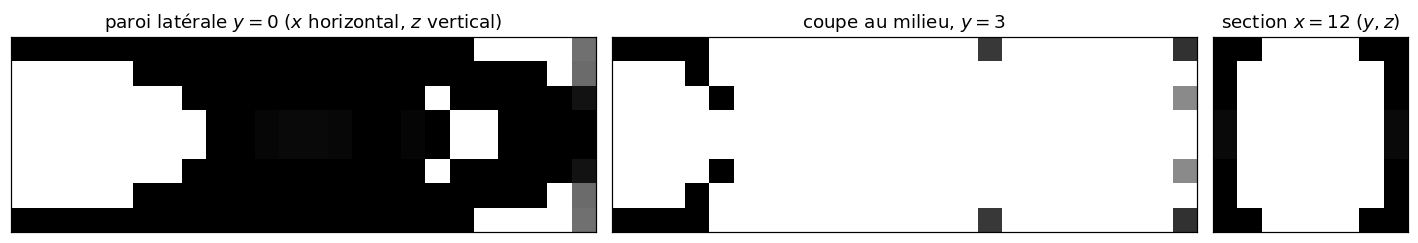

In [14]:
o3, f3 = cas((24, 8, 8), "cantilever")
t0 = time.perf_counter()
x3, h3 = mini_top88(o3, f3, 0.3, 3.0, 60)
print(f"3D : {o3.grid.n_elems} éléments, {o3.n_dofs} ddl ; 60 itérations en {time.perf_counter() - t0:.1f} s")
print(f"compliance {h3['C'][0]:.1f} -> {h3['C'][-1]:.2f} ; volume {x3.mean():.4f} ; gris {100 * grise(x3):.1f} % ; variation max finale {h3['dx'][-1]:.1e}")

v = x3.reshape(24, 8, 8)                             # (x, y, z)
anneau = np.zeros((8, 8), bool); anneau[[0, 7], :] = True; anneau[:, [0, 7]] = True   # peau de la section (y, z)
print(f"la peau de la section ({100 * anneau.mean():.0f} % des éléments) porte {100 * (v * anneau).sum() / v.sum():.0f} % de la matière")
print(f"dont les deux parois latérales y = 0 et y = 7 ({100 * 2 / 8:.0f} % des éléments) : {100 * v[:, [0, 7], :].sum() / v.sum():.0f} %")

fig, ax = plt.subplots(1, 3, figsize=(13, 2.6), gridspec_kw={"width_ratios": [3, 3, 1]})
ax[0].imshow(v[:, 0].T, origin="lower", cmap="gray_r", vmin=0, vmax=1); ax[0].set_title("paroi latérale $y=0$ ($x$ horizontal, $z$ vertical)")
ax[1].imshow(v[:, 3].T, origin="lower", cmap="gray_r", vmin=0, vmax=1); ax[1].set_title("coupe au milieu, $y=3$")
ax[2].imshow(v[12].T, origin="lower", cmap="gray_r", vmin=0, vmax=1); ax[2].set_title("section $x=12$ ($y,z$)")
for a_ in ax: a_.set_xticks([]); a_.set_yticks([])
plt.tight_layout(); plt.show()

Le résultat est creux : la peau de la section (44 % des éléments) porte 87 % de la matière, dont 58 % dans les deux **parois latérales** ($y=0$ et $y=7$, des plaques d'un élément d'épaisseur, pleines sur presque toute la longueur) et le reste dans des **semelles** haute et basse, localisées près de l'encastrement et de l'extrémité ; le cœur est vide. C'est la forme attendue pour une console chargée en flexion (la matière va loin de l'axe neutre). À $24\times8\times8$ éléments et sans filtre, il faut y voir une démonstration que le code est indépendant de la dimension, pas un design : les parois n'ont qu'un élément d'épaisseur, ce que seul un filtre (leçon 9) saurait contrôler.

## Bilan

| Constat | Où c'est dans le code |
|---|---|
| $s(\rho)=\varepsilon_s+(1-\varepsilon_s)\rho^p$ ; avec $p>1$ le gris est inefficace, avec $p=1$ le problème relâché est indifférent (deux barres) | `topopt/density.py::simp`, test C-SIMP-01 |
| $\mathcal C=\mathbf f^\top\mathbf u$ ; gradient $\le0$ partout (plus de matière n'aide qu'en rigidité) | `objectives/mechanical.py`, adjoint (notebook 7) |
| OC : point fixe $\rho_e B_e^{1/2}$, limité par `move` et les bornes, $\Lambda$ par bissection sur le volume | `optim/oc.py::OC`, tests C-OPT-01 et C-OPT-03 (moitié OC) |
| La boucle SIMP + adjoint + OC reproduit un top88 indépendant (compliances à $10^{-9}$, densité à $10^{-8}$) | `tests/integration/test_mini_top88.py` |
| Résultat MBB 60×20 net (peu de gris), conditions KKT vérifiées | §5 |
| $p=1$ donne du gris trompeur ; $p=3$ du noir et blanc ; le design à $p=3$ direct est un minimum local battu par un départ à $p=2$ | §6 |
| Sans filtre : barres de plus en plus fines avec le maillage, et damiers numériquement trop raides (3 à 4 fois plus que le gris pénalisé) | §7 |
| Appuis et charges testés (modes rigides, équilibre des réactions) | `fem/bc.py`, tests C-BC-01 à 04 |

**Limites à retenir.**
- **OC ne traite qu'une contrainte** (le volume) et suppose un objectif de type compliance ($\partial\mathcal C/\partial\rho\le0$). Dès qu'on ajoute l'aérodynamique ou plusieurs contraintes, il faut MMA (leçon 10).
- **Pas de garantie de décroissance monotone ni de minimum global** : le résultat dépend du départ ($\rho=V^{*}$ partout) et de $p$.
- **Sans filtre, le problème est mal posé** (§7). Les chiffres de ce notebook (compliance, finesse des barres) ne sont donc pas des résultats « physiques » ; ils servent à valider la chaîne.
- **Minima locaux** (§6) : le design à $p=3$ depuis $\rho=V^{*}$ est battu par un design venu de $p=2$.
- **Le benchmark filtré du contrat C-OPT-02** (MBB 60×20, $R=1{,}5h$, compliance à ±2 % du top88 recalculé) vient avec le filtre de la leçon 9 ; l'oracle `top88_numpy` le supporte déjà (`ft=1` ou `2`), mais ce n'est pas validé ici.

**Pour expérimenter.** (i) Au §4, remplacez `ScipyDirect()` par `TorchCG(tol=1e-8)` : le résultat change-t-il ? Quel est l'effet d'un CG lâche (`tol=1e-2`) sur la suite de compliances ? (ii) Au §5, démarrez de $\rho=0{,}9$ au lieu de $V^{*}$ (le volume est alors violé au départ) : que fait l'OC à la première itération ? (iii) Au §6, essayez $p=3$ avec `move=0.05` ou `0.5` : vitesse et qualité du résultat. (iv) Au §7, comparez la part de blocs en damier pour $p=2$ et $p=4$. (v) Au §8, passez à $\varepsilon_s=10^{-3}$ (argument `eps_s` de `simp`, dans `mini_top88`) : la compliance finale change-t-elle ?

*Suite : leçon 9 (filtres, projection et continuation, qui supprime les damiers et la dépendance au maillage). Voir le [plan des leçons](README.md).*